<a href="https://colab.research.google.com/github/PoojithaUndavalli/Pre-trained-CNN-models-VGG16-ResNet50-/blob/main/DL_Exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

import tensorflow as tf

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.applications import VGG16, ResNet50

from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess

from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("Original Training data:", x_train.shape)
print("Original Testing data :", x_test.shape)

Original Training data: (50000, 32, 32, 3)
Original Testing data : (10000, 32, 32, 3)


In [ ]:
x_train = x_train[:1000]
y_train = y_train[:1000]

x_test = x_test[:200]
y_test = y_test[:200]

print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)

Training images: (1000, 32, 32, 3)
Testing images : (200, 32, 32, 3)


In [ ]:
x_train = tf.image.resize(x_train, (224, 224))
x_test = tf.image.resize(x_test, (224, 224))

print(x_train.shape)
print(x_test.shape)

(1000, 224, 224, 3)
(200, 224, 224, 3)


In [ ]:
vgg = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

vgg.trainable = False

vgg_model = Sequential([
    vgg,
    GlobalAveragePooling2D(),
    Dense(10, activation="softmax")
])

vgg_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,719,818 (56.15 MB)

 Trainable params: 5,130 (20.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
x_train_vgg = vgg_preprocess(x_train.numpy())

start = time.time()

vgg_history = vgg_model.fit(
    x_train_vgg,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

vgg_time = time.time() - start

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 213ms/step - accuracy: 0.6744 - loss: 0.9852 - val_accuracy: 0.6600 - val_loss: 1.0756
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 213ms/step - accuracy: 0.7333 - loss: 0.8188 - val_accuracy: 0.6700 - val_loss: 1.0028
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 6s 220ms/step - accuracy: 0.7844 - loss: 0.6973 - val_accuracy: 0.6600 - val_loss: 0.9448
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 225ms/step - accuracy: 0.8100 - loss: 0.5935 - val_accuracy: 0.6900 - val_loss: 0.9250
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 238ms/step - accuracy: 0.8411 - loss: 0.5153 - val_accuracy: 0.6900 - val_loss: 0.9047
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 242ms/step - accuracy: 0.8700 - loss: 0.4587 - val_accuracy: 0.7100 - val_loss: 0.8971
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 235ms/step - accuracy: 0.8800 - loss: 0.4129 - val_accuracy: 0.7100 - val_loss: 0.8616
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 7s 224ms/step - accuracy: 0.8944 - loss: 0.3771 - val_accuracy: 0.

In [ ]:
x_test_vgg = vgg_preprocess(x_test.numpy())

vgg_loss, vgg_accuracy = vgg_model.evaluate(
    x_test_vgg,
    y_test
)

print("VGG16 Accuracy:", vgg_accuracy)
print("VGG16 Training Time:", vgg_time)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 165ms/step - accuracy: 0.6700 - loss: 1.0081
VGG16 Accuracy: 0.6700000166893005
VGG16 Training Time: 66.85690999031067


7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 380ms/step


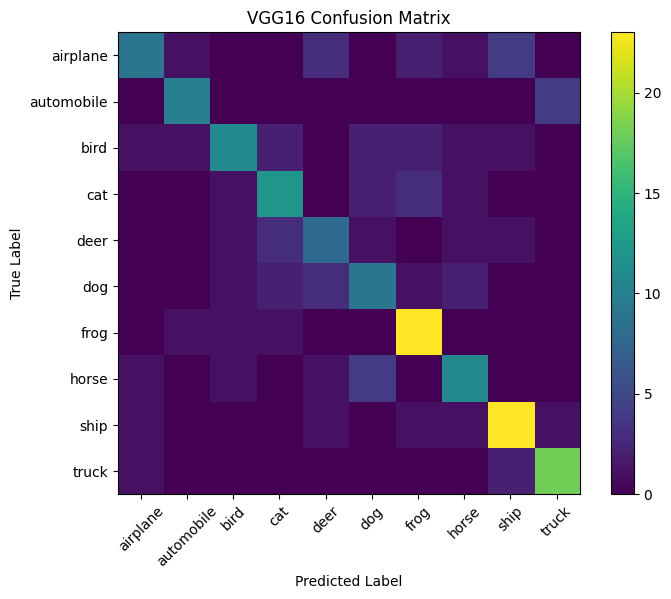

In [ ]:
# VGG16 predictions
vgg_predictions = vgg_model.predict(x_test_vgg)

vgg_pred_labels = np.argmax(vgg_predictions, axis=1)
vgg_true_labels = y_test.flatten()

# Confusion matrix
vgg_cm = confusion_matrix(
    vgg_true_labels,
    vgg_pred_labels
)

# Plot
plt.figure(figsize=(8, 6))

plt.imshow(vgg_cm)

plt.title("VGG16 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar()

plt.xticks(
    range(10),
    ["airplane", "automobile", "bird", "cat", "deer",
     "dog", "frog", "horse", "ship", "truck"],
    rotation=45
)

plt.yticks(
    range(10),
    ["airplane", "automobile", "bird", "cat", "deer",
     "dog", "frog", "horse", "ship", "truck"]
)

plt.show()

In [ ]:
resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet.trainable = False

resnet_model = Sequential([
    resnet,
    GlobalAveragePooling2D(),
    Dense(10, activation="softmax")
])

resnet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
x_train_resnet = resnet_preprocess(x_train.numpy())

start = time.time()

resnet_history = resnet_model.fit(
    x_train_resnet,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

resnet_time = time.time() - start

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 29s 479ms/step - accuracy: 0.4822 - loss: 1.5164 - val_accuracy: 0.7600 - val_loss: 0.7364
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.8367 - loss: 0.5378 - val_accuracy: 0.8300 - val_loss: 0.4857
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - accuracy: 0.8956 - loss: 0.3685 - val_accuracy: 0.8500 - val_loss: 0.4186
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.9178 - loss: 0.2782 - val_accuracy: 0.8300 - val_loss: 0.3935
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 124ms/step - accuracy: 0.9522 - loss: 0.2065 - val_accuracy: 0.8600 - val_loss: 0.3761
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.9689 - loss: 0.1661 - val_accuracy: 0.8600 - val_loss: 0.3692
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.9867 - loss: 0.1295 - val_accuracy: 0.8500 - val_loss: 0.3744
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 116ms/step - accuracy: 0.9956 - loss: 0.1048 - val_accuracy: 0

In [ ]:
x_test_resnet = resnet_preprocess(x_test.numpy())

resnet_loss, resnet_accuracy = resnet_model.evaluate(
    x_test_resnet,
    y_test
)

print("ResNet50 Accuracy:", resnet_accuracy)
print("ResNet50 Training Time:", resnet_time)

7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 674ms/step - accuracy: 0.8200 - loss: 0.5789
ResNet50 Accuracy: 0.8199999928474426
ResNet50 Training Time: 61.38111114501953


7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 648ms/step


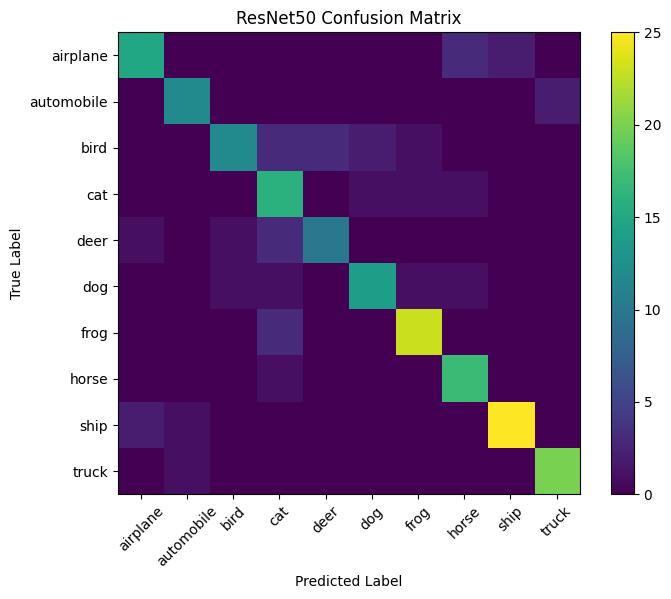

In [ ]:
# ResNet50 predictions
resnet_predictions = resnet_model.predict(x_test_resnet)

resnet_pred_labels = np.argmax(
    resnet_predictions,
    axis=1
)

resnet_true_labels = y_test.flatten()

# Confusion matrix
resnet_cm = confusion_matrix(
    resnet_true_labels,
    resnet_pred_labels
)

# Plot
plt.figure(figsize=(8, 6))

plt.imshow(resnet_cm)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.colorbar()

plt.xticks(
    range(10),
    ["airplane", "automobile", "bird", "cat", "deer",
     "dog", "frog", "horse", "ship", "truck"],
    rotation=45
)

plt.yticks(
    range(10),
    ["airplane", "automobile", "bird", "cat", "deer",
     "dog", "frog", "horse", "ship", "truck"]
)

plt.show()

In [ ]:
print("========== PERFORMANCE COMPARISON ==========")

print("\nVGG16")
print("Accuracy :", vgg_accuracy)
print("Loss     :", vgg_loss)
print("Time     :", vgg_time, "seconds")

print("\nResNet50")
print("Accuracy :", resnet_accuracy)
print("Loss     :", resnet_loss)
print("Time     :", resnet_time, "seconds")

========== PERFORMANCE COMPARISON ==========

VGG16
Accuracy : 0.6700000166893005
Loss     : 1.008081316947937
Time     : 66.85690999031067 seconds

ResNet50
Accuracy : 0.8199999928474426
Loss     : 0.578860878944397
Time     : 61.38111114501953 seconds


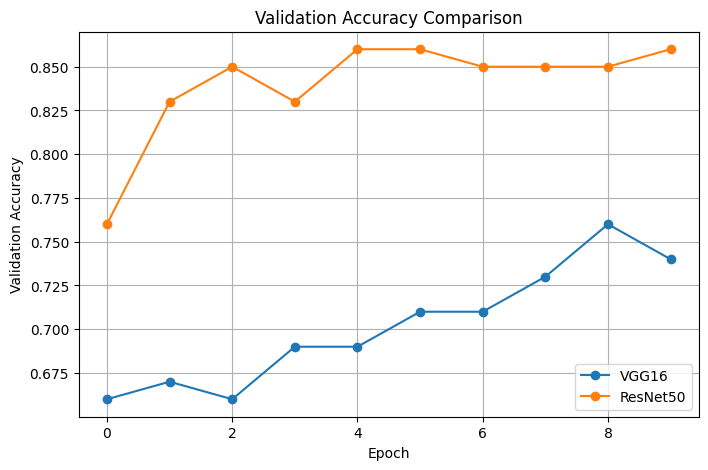

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    vgg_history.history["val_accuracy"],
    marker="o",
    label="VGG16"
)

plt.plot(
    resnet_history.history["val_accuracy"],
    marker="o",
    label="ResNet50"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy Comparison")

plt.legend()
plt.grid(True)

plt.show()

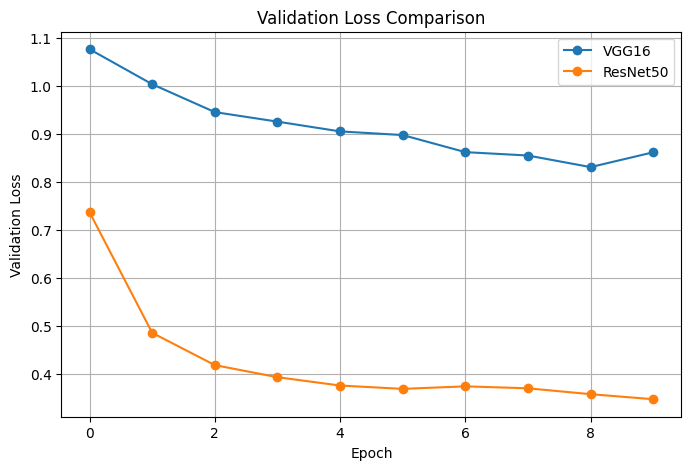

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    vgg_history.history["val_loss"],
    marker="o",
    label="VGG16"
)

plt.plot(
    resnet_history.history["val_loss"],
    marker="o",
    label="ResNet50"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")

plt.legend()
plt.grid(True)

plt.show()